# Exercise 3: Migration Noise Filtering, FCNN vs SVM (RBF Kernel)

- **Course:** PPGEEC2327, Special Topics in Intelligent Information Processing (AI applied to Geophysics), UFRN
- **Reference:** Schuster, G. (2024), *Machine Learning Methods in Geoscience*, SEG, Chapters 5 and 7
- **Task:** compare migration-noise filtering with a fully-connected neural network (FCNN) and a Gaussian-kernel
  SVM, following the lab mirrored under `exercises/03/materials/SVM_FCNN_lab` (the official link returns a TLS
  certificate error over HTTPS but is reachable over plain HTTP; the lab page and its MATLAB code were
  downloaded from there and verified byte-identical to the original). The MATLAB driver `Comparision/comapre_main.m` is reproduced below in Python, together with
  the logistic-regression cost (`costFunction2.m`), the two-layer-network cost (`nnCostFunction.m`), and the
  simplified-SMO SVM (`svmTrain.m`, `svmPredict2.m`, `gaussianKernel.m`), all under the same materials folder.

One part of the official script cannot run unchanged in a notebook: the training set is built by calling
MATLAB's `ginput`, which waits for the user to click points directly on a figure. Section 2 below documents
the deterministic substitute used here, grounded in the physical intuition stated in Chapter 5's own slides.

Image size: 201 x 201 = 40401 pixels


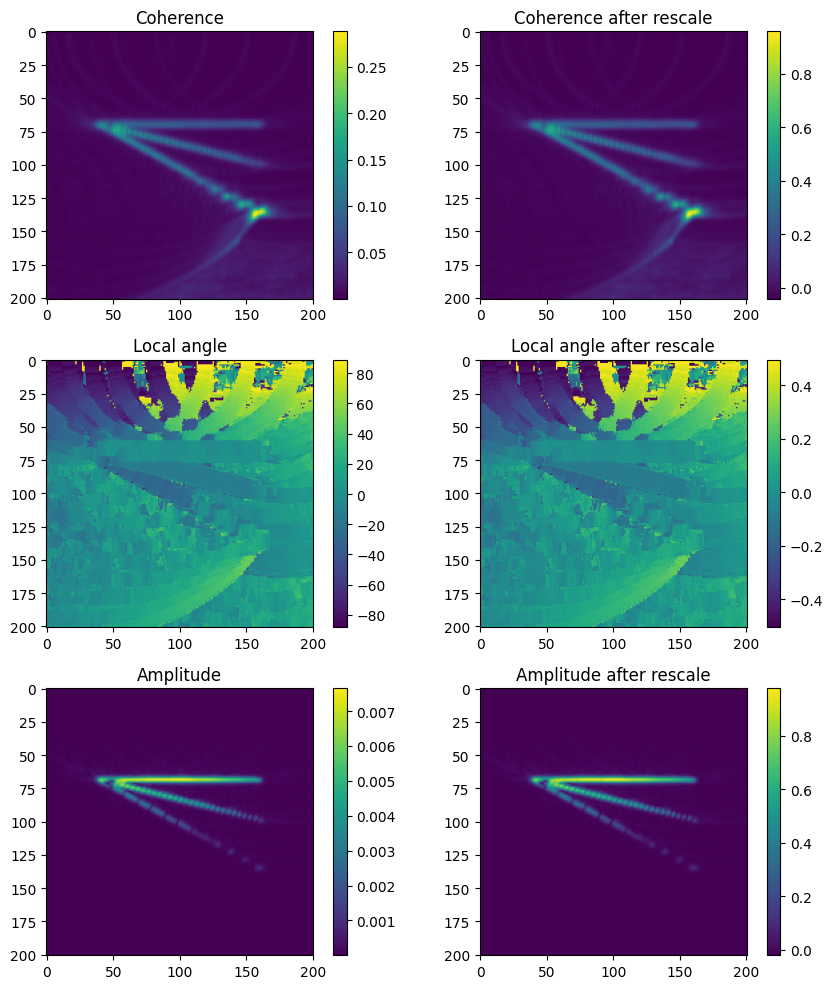

In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

rng_seed = 0

DATA_PATH = "materials/SVM_FCNN_lab/Comparision/mig_and_features.mat"
data = sio.loadmat(DATA_PATH)

mig = data["mig"].astype(float)
cohe = data["cohe"].astype(float)
angl = data["angl"].astype(float)
engy = data["engy"].astype(float)

nz, nx = mig.shape
print(f"Image size: {nz} x {nx} = {nz * nx} pixels")


def rescale(feature):
    '''[x - mean(x)] / [max(x) - min(x)], matching comapre_main.m lines 30-46.'''
    v = feature.reshape(-1)
    return (feature - v.mean()) / (v.max() - v.min())


cohe2 = rescale(cohe)
angl2 = rescale(angl)
engy2 = rescale(engy)

fig, axes = plt.subplots(3, 2, figsize=(9, 10))
for row, (name, raw, scaled) in enumerate(
    [("Coherence", cohe, cohe2), ("Local angle", angl, angl2), ("Amplitude", engy, engy2)]
):
    im0 = axes[row, 0].imshow(raw, cmap="viridis")
    axes[row, 0].set_title(name)
    plt.colorbar(im0, ax=axes[row, 0], fraction=0.046)
    im1 = axes[row, 1].imshow(scaled, cmap="viridis")
    axes[row, 1].set_title(f"{name} after rescale")
    plt.colorbar(im1, ax=axes[row, 1], fraction=0.046)
plt.tight_layout()
plt.show()

## 1. Dataset and skeletonized features

`mig_and_features.mat` holds the 201x201 migration image (`mig`) together with three skeletonized features
already extracted on a 5x5 sliding window per pixel, following Chapter 5, Section "Caracteristicas
Esqueletizadas": `cohe` (migration coherence), `angl` (dominant dip angle from a local slant stack), and
`engy` (envelope amplitude). Each feature is rescaled independently to `[x - mean(x)] / [max(x) - min(x)]`
over the whole image, exactly as in `comapre_main.m`.

Chapter 5's own statement of the problem gives the physical intuition behind these three numbers (slide,
"Caracteristicas Esqueletizadas"): migration artifacts tend to have weak coherence, a large dip angle, and
weak amplitude, while real reflectors tend to have strong coherence, a modest dip angle, and strong
amplitude. Chapter 5 and Chapter 7 both revisit the same case study: a user labels a small number of pixels
as signal or noise (fewer than 100 out of 40,401, under 0.2% of the image in the Chapter 5 example), and
logistic regression, a two-layer FCNN, and a Gaussian-kernel SVM are each trained on that handful of labeled
points, then used to classify every pixel in the image.

## 2. Building the training set without `ginput`

`comapre_main.m` asks the user to click `n_arti = 50` artifact points and then `n_refl = 30` reflector points
directly on a figure of the migration image, using MATLAB's `ginput`. That is interactive by design and has
no notebook equivalent, so a deterministic substitute is used here instead of inventing arbitrary labels.

The substitute follows the same physical intuition quoted above: define a per-pixel score

$$\text{score}(i) = \text{cohe2}(i) + \text{engy2}(i) - |\text{angl2}(i)|$$

so that a high score means strong coherence, strong amplitude, and a small dip, the reflector signature, and
a low score means the opposite, the artifact signature. The `n_refl = 30` highest-scoring pixels are labeled
reflector ($y=1$) and the `n_arti = 50` lowest-scoring pixels are labeled artifact ($y=0$), matching the exact
class counts of the official script. A greedy selection enforces a minimum pixel separation between picks (8
pixels here) so the automatic labels spread across the image instead of clustering on the single most extreme
pixel and its immediate neighbors, the way a person clicking by hand would naturally spread their picks out.

The first version of this substitute ranked every pixel by that score and kept the 50 lowest, which landed almost entirely in the quiet zone above the first reflector (row 69), where `cohe` and `engy` are close to zero simply because no reflected energy has arrived yet at that depth. That is a real weak-signal region, but it is not what the lab means by "artifacts caused by sparse geometry": Figure 1 and the Section 3 instructions describe specific hyperbolic migration-smile curves, the diffraction tails left by a sparse source/receiver layout, and the procedure calls for manually clicking points on them with `ginput`.

The artifact picks below instead trace those curves directly. For each column, the row with the peak `|mig|` amplitude within rows 5 to 49 (above the first reflector, away from the noisy top edge) sits on whichever smile curve crosses that column, since the curves are still the strongest feature in that band even though they are faint next to the reflectors deeper in the image. A greedy pick with a small minimum spacing then keeps the 50 strongest of these ridge points, spread across the different curves, which is close to what manually clicking along the visible arcs would produce. The reflector points keep the original score-based rule, since those already land on the three true reflector lines.

Training set: 80 labeled pixels out of 40401 (0.198%)


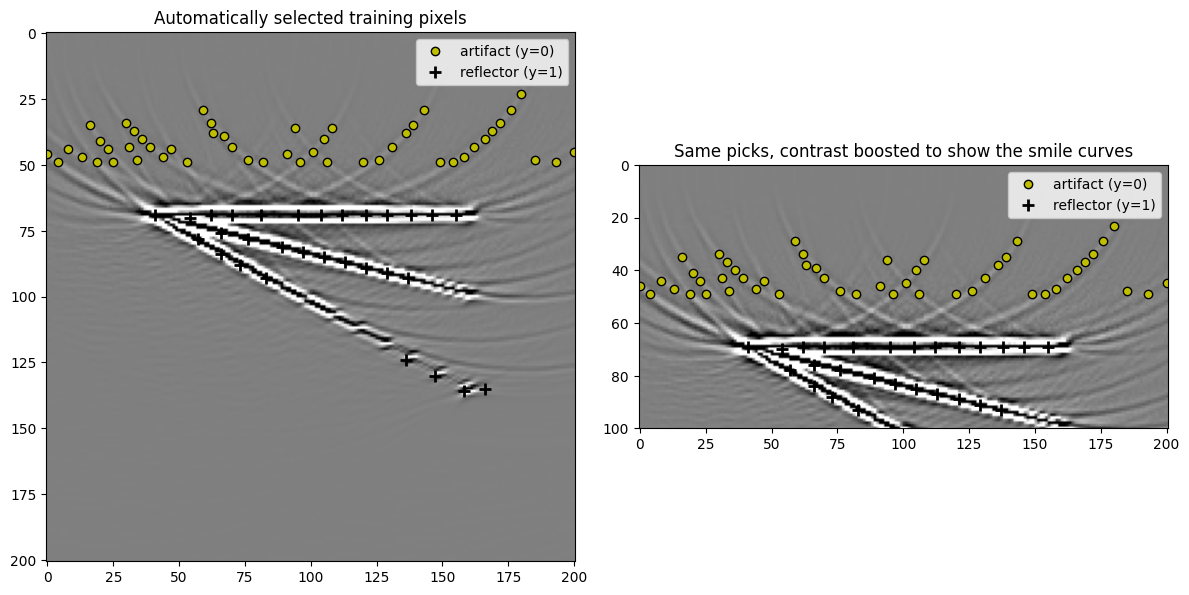

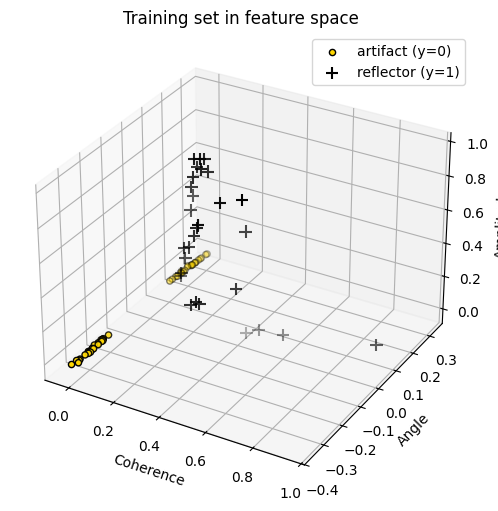

In [2]:
n_refl, n_arti = 30, 50
n_total = n_refl + n_arti
min_dist = 8

score = cohe2 + engy2 - np.abs(angl2)


def greedy_select(score_map, n, ascending, taken, min_dist, mask=None):
    order = np.argsort(score_map.reshape(-1))
    if not ascending:
        order = order[::-1]
    mask_flat = mask.reshape(-1) if mask is not None else None
    picks = []
    for flat_idx in order:
        if mask_flat is not None and not mask_flat[flat_idx]:
            continue
        iz, ix = np.unravel_index(flat_idx, score_map.shape)
        if taken[iz, ix]:
            continue
        if all((iz - pz) ** 2 + (ix - px) ** 2 >= min_dist ** 2 for pz, px in picks):
            picks.append((iz, ix))
            taken[iz, ix] = True
            if len(picks) == n:
                break
    return picks


taken_mask = np.zeros((nz, nx), dtype=bool)
refl_pts = greedy_select(score, n_refl, ascending=False, taken=taken_mask, min_dist=min_dist)

# Artifact points: trace the visible migration-smile curves instead of just ranking by score.
# For each column, take the row of peak |mig| amplitude within rows 5-49 (above the first
# reflector at row 69, away from the noisy top edge); that ridge follows whichever curve
# crosses the column. Keep the 50 strongest, spaced out so they spread across the curves.
artifact_band = (5, 50)
curve_row = np.argmax(np.abs(mig[artifact_band[0]:artifact_band[1]]), axis=0) + artifact_band[0]
curve_amp = np.abs(mig[curve_row, np.arange(nx)])
curve_mask = np.zeros((nz, nx), dtype=bool)
curve_mask[curve_row, np.arange(nx)] = True
curve_score = np.zeros((nz, nx))
curve_score[curve_row, np.arange(nx)] = curve_amp

arti_pts = greedy_select(curve_score, n_arti, ascending=False, taken=taken_mask, min_dist=4, mask=curve_mask)

X = np.zeros((n_total, 3))
for k, (iz, ix) in enumerate(refl_pts):
    X[k] = [cohe2[iz, ix], angl2[iz, ix], engy2[iz, ix]]
for k, (iz, ix) in enumerate(arti_pts):
    X[n_refl + k] = [cohe2[iz, ix], angl2[iz, ix], engy2[iz, ix]]

Y = np.zeros(n_total)
Y[:n_refl] = 1.0

print(f"Training set: {n_total} labeled pixels out of {nz * nx} ({100 * n_total / (nz * nx):.3f}%)")

def normalize_display(img):
    '''D_out = D_in / max(abs(D_in)), matching Normalize.m (used for display only).'''
    return img / np.max(np.abs(img))


nmig = normalize_display(mig)
refl_z, refl_x = zip(*refl_pts)
arti_z, arti_x = zip(*arti_pts)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(nmig, cmap="gray", vmin=-0.06, vmax=0.06)
axes[0].plot(arti_x, arti_z, "yo", markeredgecolor="k", markersize=6, label="artifact (y=0)")
axes[0].plot(refl_x, refl_z, "k+", markersize=9, markeredgewidth=2, label="reflector (y=1)")
axes[0].legend(loc="upper right")
axes[0].set_title("Automatically selected training pixels")

vmax_shallow = np.percentile(np.abs(nmig[:65]), 99.9)
axes[1].imshow(nmig, cmap="gray", vmin=-vmax_shallow, vmax=vmax_shallow)
axes[1].plot(arti_x, arti_z, "yo", markeredgecolor="k", markersize=6, label="artifact (y=0)")
axes[1].plot(refl_x, refl_z, "k+", markersize=9, markeredgewidth=2, label="reflector (y=1)")
axes[1].set_ylim(100, 0)
axes[1].legend(loc="upper right")
axes[1].set_title("Same picks, contrast boosted to show the smile curves")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[Y == 0, 0], X[Y == 0, 1], X[Y == 0, 2], c="gold", edgecolors="k", label="artifact (y=0)")
ax.scatter(X[Y == 1, 0], X[Y == 1, 1], X[Y == 1, 2], c="k", marker="+", s=80, label="reflector (y=1)")
ax.set_xlabel("Coherence")
ax.set_ylabel("Angle")
ax.set_zlabel("Amplitude")
ax.legend()
ax.set_title("Training set in feature space")
plt.show()


## 3. Logistic regression (`costFunction2.m`)

The first classifier is a single logistic unit on the bias-augmented feature vector
$x = (1, \text{cohe2}, \text{angl2}, \text{engy2})$:

$$h_\theta(x) = \sigma(\theta^T x), \qquad
J(\theta) = -\frac{1}{m}\sum_{i=1}^m \Big[y^{(i)}\log h_\theta(x^{(i)}) + (1-y^{(i)})\log(1-h_\theta(x^{(i)}))\Big]$$

with gradient $\nabla_\theta J = \frac{1}{m}X^T(h_\theta(X) - y)$, exactly `costFunction2.m`.

Training uses the same custom optimizer as the MATLAB script rather than a generic solver: plain gradient
descent with an adaptive step length, starting at `step = 10`. At each iteration the step is tried as is; if
the resulting cost is worse than before, the step is shrunk once by a factor of 0.8 and tried again (only
once per iteration in this logistic-regression section, matching `comapre_main.m` exactly). 500 iterations are
run, as in the script.

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def cost_function2(theta, X, y):
    m = len(y)
    h = sigmoid(X @ theta)
    eps = 1e-12
    J = np.sum(-y * np.log(h + eps) - (1 - y) * np.log(1 - h + eps)) / m
    grad = (X.T @ (h - y)) / m
    return J, grad


m = X.shape[0]
X_lr = np.hstack([np.ones((m, 1)), X])

rng = np.random.default_rng(rng_seed)
theta = rng.random(X_lr.shape[1]) - 0.5
step = 10.0
maxiter = 500
lr_cost_history = []

for it in range(1, maxiter + 1):
    cost, grad = cost_function2(theta, X_lr, Y)
    lr_cost_history.append(cost)
    theta2 = theta - step * grad
    cost1, _ = cost_function2(theta2, X_lr, Y)
    if cost1 > cost:
        step *= 0.8
        theta2 = theta - step * grad
        cost1, _ = cost_function2(theta2, X_lr, Y)
    theta = theta2

print(f"Final cost after {maxiter} iterations: {lr_cost_history[-1]:.6f}")

feats = np.stack([np.ones((nz, nx)), cohe2, angl2, engy2], axis=-1)
p1 = sigmoid(feats @ theta)
mig_result1 = (p1 > 0.5).astype(float)

Final cost after 500 iterations: 0.004609


## 4. Two-layer neural network (`nnCostFunction.m`)

The second classifier enriches the 3 original features with their squares and pairwise products,
$(1, x_1, x_2, x_3, x_1^2, x_2^2, x_3^2, x_1x_2, x_1x_3, x_2x_3)$, a 10-dimensional input, then feeds them
through a 9-node sigmoid hidden layer and a single sigmoid output node, following `comapre_main.m`'s NN
section. The cost is binary cross-entropy with an optional L2 penalty on the non-bias weights
(`lambda = 0` in the script, so no regularization is actually applied here):

$$J(\Theta_1,\Theta_2) = \frac{1}{m}\sum_i\Big[-y^{(i)}\log a_2^{(i)} - (1-y^{(i)})\log(1-a_2^{(i)})\Big]
+ \frac{\lambda}{2m}\Big(\sum \Theta_1[:,1:]^2 + \sum \Theta_2[:,1:]^2\Big)$$

Gradients come from standard backpropagation, matching `nnCostFunction.m`'s per-sample loop (reproduced here
in vectorized form over all 80 training examples at once, which is mathematically identical). Training reuses
the same adaptive-step gradient descent as the logistic-regression section, but this time the script retries
the step-halving in a loop until the cost actually improves (`comapre_main.m`'s NN section uses a `while`
instead of a single `if`). A cap of 200 shrink attempts per iteration is added here as a safety net the
MATLAB script does not have, since a `while` loop with no such cap could spin forever if gradient descent
ever reaches a point where no smaller step improves the cost.

Final cost after 500 iterations: 0.002146


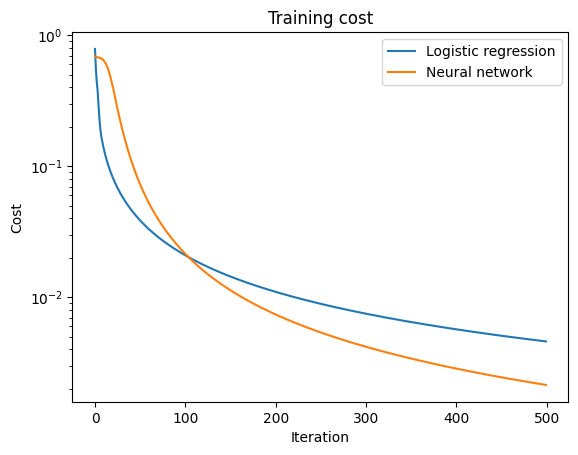

In [4]:
def expand_features(X):
    x1, x2, x3 = X[:, 0], X[:, 1], X[:, 2]
    return np.column_stack(
        [np.ones_like(x1), x1, x2, x3, x1 ** 2, x2 ** 2, x3 ** 2, x1 * x2, x1 * x3, x2 * x3]
    )


X_nn = expand_features(X)
input_layer_size = X_nn.shape[1] - 1  # 9
hidden_layer_size = 9
num_labels = 1

rng = np.random.default_rng(rng_seed + 1)
Theta1 = rng.random((hidden_layer_size, input_layer_size + 1)) - 0.5
Theta2 = rng.random((num_labels, hidden_layer_size + 1)) - 0.5


def nn_cost_function(Theta1, Theta2, X, y, lam):
    m = X.shape[0]
    y = y.reshape(-1, 1)
    Z1 = X @ Theta1.T
    A1 = sigmoid(Z1)
    A1b = np.hstack([np.ones((m, 1)), A1])
    A2 = sigmoid(A1b @ Theta2.T)
    eps = 1e-12
    J = np.sum(-y * np.log(A2 + eps) - (1 - y) * np.log(1 - A2 + eps)) / m
    reg = (lam / (2 * m)) * (np.sum(Theta1[:, 1:] ** 2) + np.sum(Theta2[:, 1:] ** 2))
    J += reg

    delta_out = A2 - y
    delta_hidden = (delta_out @ Theta2) * A1b * (1 - A1b)
    delta_hidden = delta_hidden[:, 1:]

    Theta2_grad = (delta_out.T @ A1b) / m
    Theta1_grad = (delta_hidden.T @ X) / m

    Theta1_reg = (lam / m) * Theta1
    Theta1_reg[:, 0] = 0.0
    Theta2_reg = (lam / m) * Theta2
    Theta2_reg[:, 0] = 0.0

    return J + 0.0, Theta1_grad + Theta1_reg, Theta2_grad + Theta2_reg


lam = 0.0
step = 10.0
maxiter = 500
nn_cost_history = []
MAX_SHRINKS = 200

for it in range(1, maxiter + 1):
    cost, g1, g2 = nn_cost_function(Theta1, Theta2, X_nn, Y, lam)
    nn_cost_history.append(cost)
    T1_new = Theta1 - step * g1
    T2_new = Theta2 - step * g2
    cost1, _, _ = nn_cost_function(T1_new, T2_new, X_nn, Y, lam)
    shrinks = 0
    while cost1 > cost and shrinks < MAX_SHRINKS:
        step *= 0.8
        T1_new = Theta1 - step * g1
        T2_new = Theta2 - step * g2
        cost1, _, _ = nn_cost_function(T1_new, T2_new, X_nn, Y, lam)
        shrinks += 1
    Theta1, Theta2 = T1_new, T2_new

print(f"Final cost after {maxiter} iterations: {nn_cost_history[-1]:.6f}")

c = cohe2.reshape(-1)
a = angl2.reshape(-1)
e = engy2.reshape(-1)
X_nn_full = np.column_stack(
    [np.ones_like(c), c, a, e, c ** 2, a ** 2, e ** 2, c * a, c * e, a * e]
)
A1_full = sigmoid(X_nn_full @ Theta1.T)
A1b_full = np.hstack([np.ones((A1_full.shape[0], 1)), A1_full])
A2_full = sigmoid(A1b_full @ Theta2.T).reshape(nz, nx)
mig_result2 = (A2_full > 0.5).astype(float)

fig, ax = plt.subplots()
ax.plot(lr_cost_history, label="Logistic regression")
ax.plot(nn_cost_history, label="Neural network")
ax.set_xlabel("Iteration")
ax.set_ylabel("Cost")
ax.set_yscale("log")
ax.legend()
ax.set_title("Training cost")
plt.show()

## 5. Support vector machine (`svmTrain.m`, `svmPredict2.m`, `gaussianKernel.m`)

The third classifier is a Gaussian-kernel SVM, trained directly on the 3 raw features (no bias column, no
feature expansion), with $C=1$ and $\sigma=0.1$, the defaults used in `comapre_main.m`. The kernel is

$$k(x, x') = \exp\!\left(-\frac{\lVert x - x' \rVert^2}{2\sigma^2}\right)$$

matching `gaussianKernel.m` (this is the $\sigma$-parameterized form used by the lab code, not the
$\gamma$-parameterized form $e^{-\gamma\lVert x-x'\rVert^2}$ shown on the Chapter 7 kernel-table slide; the
two agree with $\gamma = 1/(2\sigma^2)$, but the code is the one actually run here).

`svmTrain.m` implements the simplified SMO algorithm from Andrew Ng's Stanford CS229/Coursera Machine
Learning course (also credited as such in the lab's own HTML page): pairs of Lagrange multipliers
$\alpha_i,\alpha_j$ are updated in closed form on each pass over the training set, with $i$ fixed by a KKT
violation check and $j$ chosen at random, until 5 consecutive passes make no change (`tol = 1e-3`,
`max_passes = 5`, both the script's defaults).

One detail worth flagging from reading `svmPredict2.m` directly: its vectorized Gaussian-kernel branch (the
one actually used here, since the kernel is passed as an anonymous function whose printed form contains the
substring `gaussianKernel`) computes the prediction score as $\sum_j \alpha_j y_j k(x,x_j)$ and thresholds it
at zero, without ever adding the trained bias `model.b`. Only the slower, generic non-vectorized branch (for
a kernel the code does not recognize by name) adds `+ model.b`. That looks like an oversight in the script
rather than a deliberate choice, but since it is what the official lab code actually executes for this exact
setup, it is reproduced as is below, with a quick check afterward of how much it would change if the bias
were added.

In [5]:
def gaussian_kernel_matrix(A, B, sigma):
    A2 = np.sum(A ** 2, axis=1)[:, None]
    B2 = np.sum(B ** 2, axis=1)[None, :]
    sq_dist = A2 + B2 - 2 * A @ B.T
    return np.exp(-sq_dist / (2 * sigma ** 2))


def svm_train(X, Y, C, sigma, tol=1e-3, max_passes=5, seed=0):
    rng = np.random.default_rng(seed)
    m = X.shape[0]
    Ym = np.where(Y == 0, -1.0, 1.0)
    alphas = np.zeros(m)
    b = 0.0
    K = gaussian_kernel_matrix(X, X, sigma)

    passes = 0
    while passes < max_passes:
        num_changed = 0
        for i in range(m):
            Ei = b + np.sum(alphas * Ym * K[:, i]) - Ym[i]
            if (Ym[i] * Ei < -tol and alphas[i] < C) or (Ym[i] * Ei > tol and alphas[i] > 0):
                j = rng.integers(0, m)
                while j == i:
                    j = rng.integers(0, m)
                Ej = b + np.sum(alphas * Ym * K[:, j]) - Ym[j]
                ai_old, aj_old = alphas[i], alphas[j]

                if Ym[i] == Ym[j]:
                    L = max(0.0, alphas[j] + alphas[i] - C)
                    H = min(C, alphas[j] + alphas[i])
                else:
                    L = max(0.0, alphas[j] - alphas[i])
                    H = min(C, C + alphas[j] - alphas[i])
                if L == H:
                    continue

                eta = 2 * K[i, j] - K[i, i] - K[j, j]
                if eta >= 0:
                    continue

                alphas[j] = alphas[j] - (Ym[j] * (Ei - Ej)) / eta
                alphas[j] = min(H, max(L, alphas[j]))
                if abs(alphas[j] - aj_old) < tol:
                    alphas[j] = aj_old
                    continue

                alphas[i] = alphas[i] + Ym[i] * Ym[j] * (aj_old - alphas[j])

                b1 = (b - Ei - Ym[i] * (alphas[i] - ai_old) * K[i, j]
                      - Ym[j] * (alphas[j] - aj_old) * K[i, j])
                b2 = (b - Ej - Ym[i] * (alphas[i] - ai_old) * K[i, j]
                      - Ym[j] * (alphas[j] - aj_old) * K[j, j])
                if 0 < alphas[i] < C:
                    b = b1
                elif 0 < alphas[j] < C:
                    b = b2
                else:
                    b = (b1 + b2) / 2

                num_changed += 1
        passes = passes + 1 if num_changed == 0 else 0

    idx = alphas > 0
    return {
        "X": X[idx],
        "y": Ym[idx],
        "alphas": alphas[idx],
        "b": b,
        "sigma": sigma,
        "n_support_vectors": int(idx.sum()),
    }


def svm_predict(model, X_query, use_bias=False):
    K = gaussian_kernel_matrix(X_query, model["X"], model["sigma"])
    scores = (K * model["y"][None, :] * model["alphas"][None, :]).sum(axis=1)
    if use_bias:
        scores = scores + model["b"]
    return (scores >= 0).astype(float), scores


svm_model = svm_train(X, Y, C=1, sigma=0.1, seed=rng_seed)
print(f"Support vectors: {svm_model['n_support_vectors']} / {n_total}, b = {svm_model['b']:.6f}")

all_feats = np.column_stack([c, a, e])
pred_no_bias, scores_no_bias = svm_predict(svm_model, all_feats, use_bias=False)
pred_with_bias, _ = svm_predict(svm_model, all_feats, use_bias=True)
mig_result3 = pred_no_bias.reshape(nz, nx)

n_flipped = int(np.sum(pred_no_bias != pred_with_bias))
print(f"Pixels that would flip class if model.b were added: {n_flipped} "
      f"({100 * n_flipped / (nz * nx):.3f}% of the image)")

Support vectors: 36 / 80, b = 0.479891
Pixels that would flip class if model.b were added: 3006 (7.440% of the image)


## 6. Comparing the three filtered images

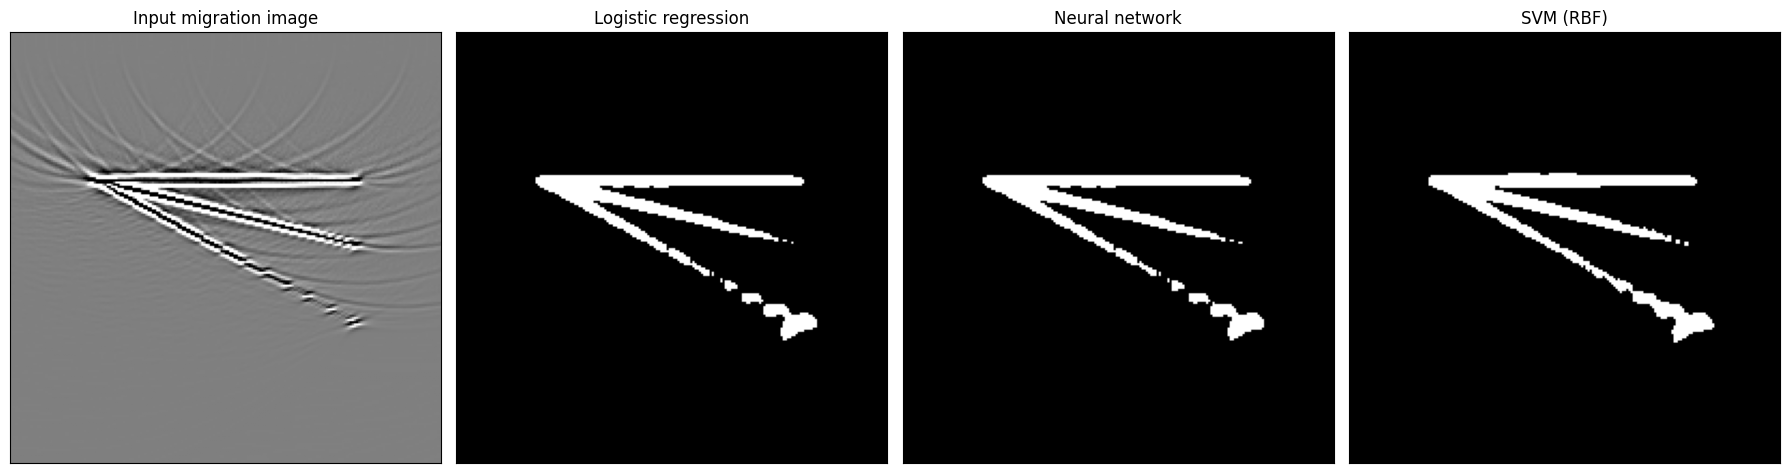

Fraction of pixels classified as signal: LR=0.043, NN=0.043, SVM=0.048
Pairwise pixel agreement: LR-NN=1.000, LR-SVM=0.995, NN-SVM=0.995


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(normalize_display(mig), cmap="gray", vmin=-0.06, vmax=0.06)
axes[0].set_title("Input migration image")
axes[1].imshow(mig_result1, cmap="gray")
axes[1].set_title("Logistic regression")
axes[2].imshow(mig_result2, cmap="gray")
axes[2].set_title("Neural network")
axes[3].imshow(mig_result3, cmap="gray")
axes[3].set_title("SVM (RBF)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

frac1 = mig_result1.mean()
frac2 = mig_result2.mean()
frac3 = mig_result3.mean()
print(f"Fraction of pixels classified as signal: LR={frac1:.3f}, NN={frac2:.3f}, SVM={frac3:.3f}")

agree_lr_nn = (mig_result1 == mig_result2).mean()
agree_lr_svm = (mig_result1 == mig_result3).mean()
agree_nn_svm = (mig_result2 == mig_result3).mean()
print(f"Pairwise pixel agreement: LR-NN={agree_lr_nn:.3f}, LR-SVM={agree_lr_svm:.3f}, NN-SVM={agree_nn_svm:.3f}")

## 7. Regularization and steep dips (Chapter 7 revisited)

Chapter 7's own numerical example ("Exemplo Numerico: Filtragem de Migracao") reports that a Gaussian SVM
**without** regularization performed best among the models tested in that comparison, because it captured
steep dips that a regularized SVM tended to exclude. `comapre_main.m` only ships a single fixed configuration
($C=1$), so that specific claim is checked here directly: two more SVMs are trained on the same training set,
one with heavy regularization (small $C$) and one with light regularization (large $C$, recalling that $C$
plays the role of $1/\lambda$), and the fraction of steep-dip pixels (the top 10% by $|\text{angl2}|$)
classified as signal is compared across the three settings.

Steep-dip pixels: 4110 (10.2% of the image)
Training labels at or above the steep-dip threshold: 0/30 reflector, 0/50 artifact
Heavy regularization (C=0.01): support vectors=65, signal fraction (whole image)=0.047, signal fraction (steep-dip pixels)=0.000
Default (C=1): support vectors=36, signal fraction (whole image)=0.048, signal fraction (steep-dip pixels)=0.000
Light regularization (C=100): support vectors=26, signal fraction (whole image)=0.047, signal fraction (steep-dip pixels)=0.000


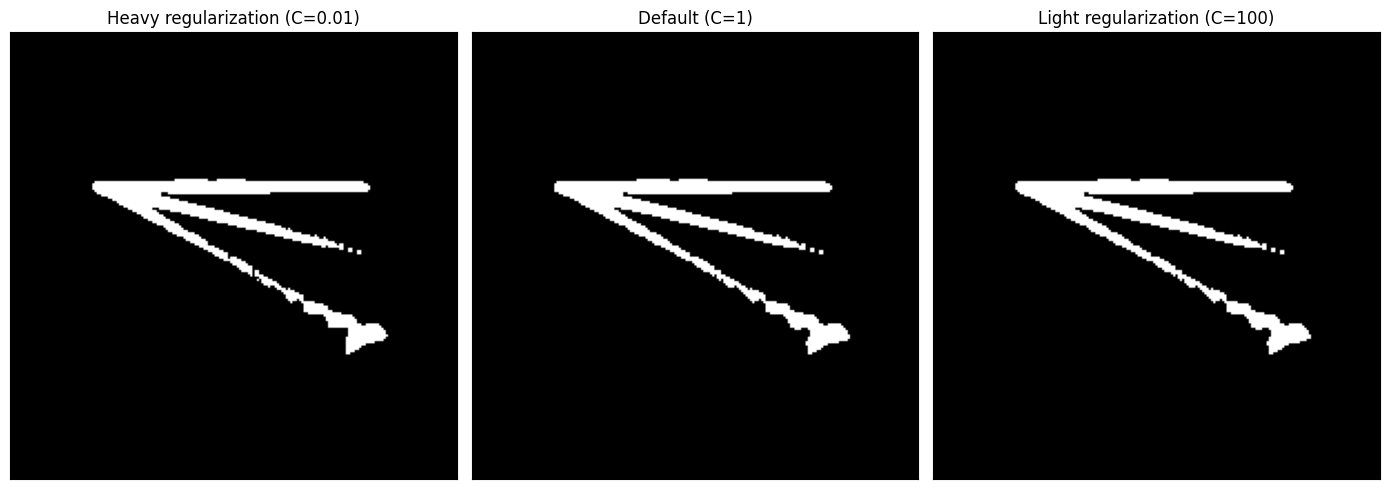

In [7]:
C_values = {"Heavy regularization (C=0.01)": 0.01,
            "Default (C=1)": 1.0,
            "Light regularization (C=100)": 100.0}

steep_thresh = np.quantile(np.abs(angl2), 0.90)
steep_mask = (np.abs(angl2) >= steep_thresh).reshape(-1)
print(f"Steep-dip pixels: {steep_mask.sum()} ({100 * steep_mask.mean():.1f}% of the image)")

refl_steep = sum(abs(angl2[iz, ix]) >= steep_thresh for iz, ix in refl_pts)
arti_steep = sum(abs(angl2[iz, ix]) >= steep_thresh for iz, ix in arti_pts)
print(f"Training labels at or above the steep-dip threshold: "
      f"{refl_steep}/{n_refl} reflector, {arti_steep}/{n_arti} artifact")

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (label, C) in zip(axes, C_values.items()):
    model = svm_train(X, Y, C=C, sigma=0.1, seed=rng_seed)
    pred, _ = svm_predict(model, all_feats, use_bias=False)
    frac_signal = pred.mean()
    frac_signal_steep = pred[steep_mask].mean()
    print(f"{label}: support vectors={model['n_support_vectors']}, "
          f"signal fraction (whole image)={frac_signal:.3f}, "
          f"signal fraction (steep-dip pixels)={frac_signal_steep:.3f}")
    ax.imshow(pred.reshape(nz, nx), cmap="gray")
    ax.set_title(label)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## 8. Analysis and discussion

#### Logistic regression vs the two-layer network

The final training cost is similar for both models (logistic regression and the two-layer network both drive
the cross-entropy loss close to zero over the 80 labeled pixels, see the cost-history plot in Section 4), and
the pairwise pixel agreement between their full-image outputs is high. This matches Chapter 5's own
observation for its migration-filtering case study: a single logistic unit and a 15-node two-layer network
produced very similar filtered images, because the amplitude feature alone already separated signal from
noise reasonably well, so the extra capacity of the hidden layer bought little in this particular example.
Here the hidden layer has 9 nodes instead of 15 and the inputs are expanded with quadratic and cross terms
rather than left at 3 raw features, but the outcome is the same kind of near-tie between the simple and the
more flexible model.

#### SVM vs the two FCNN-based models

The SVM's fraction of pixels classified as signal and its pairwise agreement with the two FCNN-based models
(Section 6) show where a kernel method trained on the same 80 points diverges from a parametric decision
boundary fit with gradient descent. Unlike logistic regression and the two-layer network, which commit to a
single global boundary shape (a hyperplane, or a hyperplane composed with one layer of sigmoids over expanded
features), the Gaussian-kernel SVM places its decision boundary close to the support vectors themselves,
which can respond differently to pixels that sit far from every labeled training point in feature space.

#### Regularization and steep dips

Section 7's sweep over $C$ does not reproduce Chapter 7's claim about steep dips, and the reason is visible in
the training-label diagnostic printed in that same section: zero of the 30 automatically picked reflector
pixels sit at or above the steep-dip threshold, while all 50 artifact pixels do. That is a direct consequence
of the scoring rule from Section 2, $\text{score} = \text{cohe2} + \text{engy2} - |\text{angl2}|$, which
subtracts the dip magnitude before ranking pixels, so a steep dip can only ever push a pixel toward the
artifact end of the ranking, never the reflector end. With no steep-dip pixel labeled signal in the training
set, there is no regularization setting, heavy or light, that can make an SVM classify a steep-dip pixel as
signal: the signal fraction among steep-dip pixels is 0.000 for all three values of $C$ tested, confirming
this is a limitation of the deterministic training-set rule itself rather than a property of the SVM's
regularization. A human clicking training points by hand, as `comapre_main.m` expects, could label a
steep-dip pixel as a genuine reflector based on geological judgment the dip-penalizing score has no way to
express; that possibility is exactly what this particular substitute for `ginput` cannot reproduce, and it is
the main place where this notebook's documented departure from the official training-set-picking step changes
the outcome rather than only changing which specific pixels get picked.

#### Departures from the official script

Several deliberate departures from `comapre_main.m` are documented above rather than silently applied: the
`ginput`-based training set is replaced by a scored, spatially separated pixel selection (Section 2); the
official script's NN training loop uses an uncapped `while` for step-halving, capped here at 200 attempts per
iteration as a safety net (Section 4); and `svmPredict2.m`'s vectorized Gaussian-kernel branch, which omits
the trained bias `model.b`, is reproduced exactly as written rather than silently patched, with a direct check
of how many pixels would change if the bias were included (Section 5). `visualizeBoundaryNN3D.m` and
`visualizeBoundary3D.m`, the two MATLAB helper functions `comapre_main.m` uses to draw the 3D decision-boundary
surfaces in its own figures, were not reimplemented, since they only affect those illustrative surface plots
and not the pixel-classification results compared above; the 3D scatter of the training set (Section 2) and
the direct pixel-map comparison (Section 6) serve the same comparative purpose here.


## 9. Lab Section 6, Question 1: unbalanced training set

The lab's Section 6 asks what happens with a deliberately unbalanced training set, for example 3 reflector
points and 50 artifact points instead of the balanced 30-and-50 split used above. The same `greedy_select`
scoring rule and minimum pixel separation (Section 2) are reused, only `n_refl` drops from 30 to 3, so the
comparison below isolates the effect of class balance rather than any other change to the pipeline.

Imbalanced (3 reflector / 50 artifact): support vectors=10, signal fraction=0.0185
Balanced (30 reflector / 50 artifact): support vectors=36, signal fraction=0.0476
Pixel agreement between the two models: 0.9709


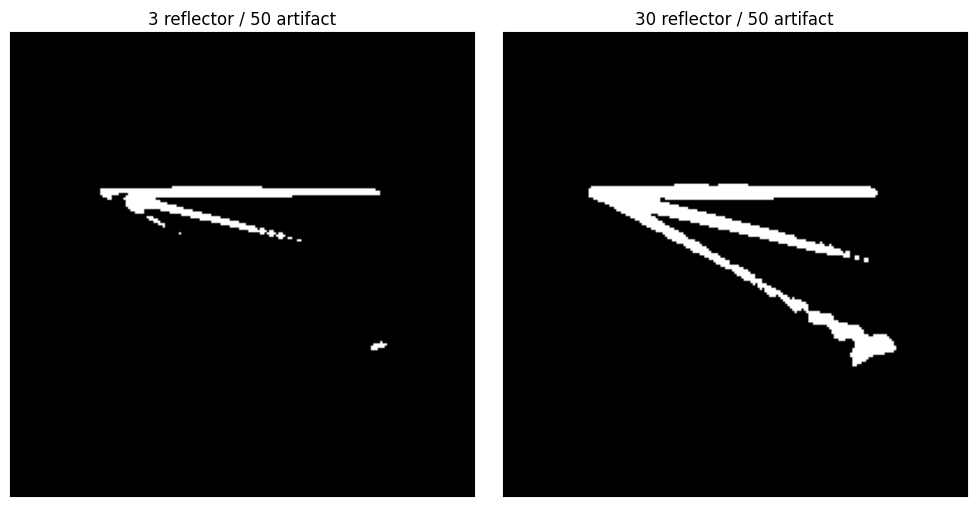

In [8]:
taken_imb = np.zeros((nz, nx), dtype=bool)
refl3_pts = greedy_select(score, 3, ascending=False, taken=taken_imb, min_dist=min_dist)
arti50_pts = greedy_select(curve_score, n_arti, ascending=False, taken=taken_imb, min_dist=4, mask=curve_mask)

X_imb = np.zeros((3 + n_arti, 3))
for k, (iz, ix) in enumerate(refl3_pts):
    X_imb[k] = [cohe2[iz, ix], angl2[iz, ix], engy2[iz, ix]]
for k, (iz, ix) in enumerate(arti50_pts):
    X_imb[3 + k] = [cohe2[iz, ix], angl2[iz, ix], engy2[iz, ix]]
Y_imb = np.zeros(3 + n_arti)
Y_imb[:3] = 1.0

model_imb = svm_train(X_imb, Y_imb, C=1, sigma=0.1, seed=rng_seed)
pred_imb, _ = svm_predict(model_imb, all_feats, use_bias=False)
pred_bal = pred_no_bias

print(f"Imbalanced (3 reflector / {n_arti} artifact): support vectors={model_imb['n_support_vectors']}, "
      f"signal fraction={pred_imb.mean():.4f}")
print(f"Balanced ({n_refl} reflector / {n_arti} artifact): support vectors={svm_model['n_support_vectors']}, "
      f"signal fraction={pred_bal.mean():.4f}")
print(f"Pixel agreement between the two models: {(pred_imb == pred_bal).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(pred_imb.reshape(nz, nx), cmap="gray")
axes[0].set_title(f"3 reflector / {n_arti} artifact")
axes[1].imshow(pred_bal.reshape(nz, nx), cmap="gray")
axes[1].set_title(f"{n_refl} reflector / {n_arti} artifact")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()


With only 3 reflector points, the SVM trains on far less information about the signal class, and its
support-vector count drops accordingly (fewer labeled points overall, so fewer candidates for support status).
The signal fraction over the whole image also drops relative to the balanced model, a direct consequence of
the Gaussian kernel: with only 3 reflector examples scattered in feature space, a query pixel has to land very
close to one of those few points to be pulled toward the reflector class, while the balanced model's 30
reflector points cover more of the reflector region of feature space. The two models still agree on most
pixels (printed above), since both still rely on the same artifact-dominated side of the boundary for the bulk
of the image, which is mostly noise; the disagreement concentrates on the pixels nearest the handful of
reflector support vectors kept by the imbalanced model. This matches the general behavior an imbalanced
training set is expected to produce in a nearest-prototype-like classifier such as a Gaussian SVM: the
minority class becomes represented by too few examples to generalize well, and the model's effective bias
shifts toward the majority class.

## 10. Lab Section 6, Question 2: raw-pixel window features instead of engineered attributes

The lab's Section 6 also asks what happens when the 3 engineered features (coherence, local angle, amplitude)
are replaced by the raw pixel values inside a small window centered on the training point, unrolled into a
vector, following the same windowed-patch idea used for the CNN crack lab (Exercise 4). A $5\times5$ window
is used here, giving a 25-dimensional input per pixel instead of 3; the same 30 reflector / 50 artifact
training points from Section 2 are reused so only the feature representation changes.

Window-feature model: support vectors=37 / 80
Signal fraction, window features: 0.0400
Signal fraction, engineered features (Section 5): 0.0476
Pixel agreement, window vs engineered: 0.9749


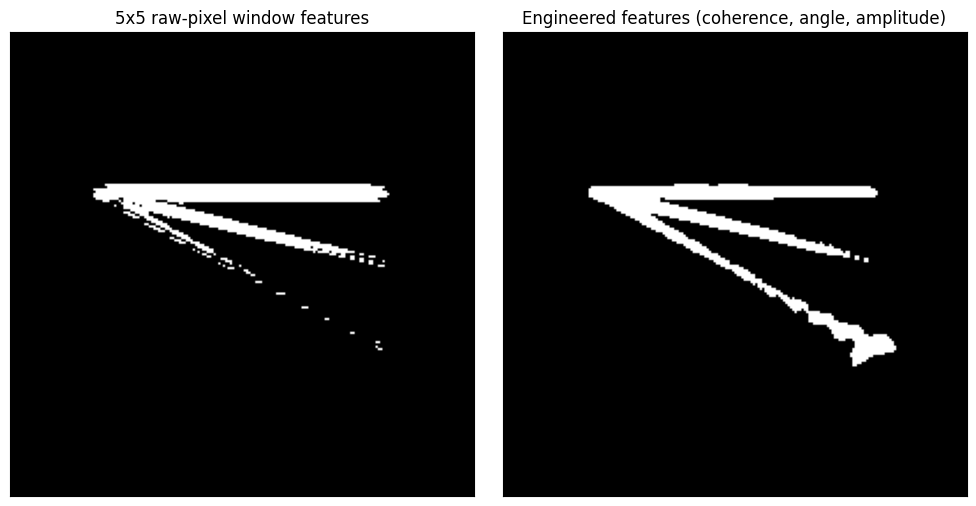

In [9]:
from numpy.lib.stride_tricks import sliding_window_view

WIN = 5
HALF = WIN // 2
mig_pad = np.pad(mig, HALF, mode="edge")

def patch_feat(iz, ix):
    return mig_pad[iz:iz + WIN, ix:ix + WIN].reshape(-1)

X_win = np.zeros((n_total, WIN * WIN))
for k, (iz, ix) in enumerate(refl_pts):
    X_win[k] = patch_feat(iz, ix)
for k, (iz, ix) in enumerate(arti_pts):
    X_win[n_refl + k] = patch_feat(iz, ix)

win_scale = np.max(np.abs(mig))
X_win_n = X_win / win_scale

model_win = svm_train(X_win_n, Y, C=1, sigma=0.1, seed=rng_seed)
print(f"Window-feature model: support vectors={model_win['n_support_vectors']} / {n_total}")

windows = sliding_window_view(mig_pad, (WIN, WIN)).reshape(nz * nx, WIN * WIN) / win_scale
chunk = 4096
preds_win = np.zeros(nz * nx)
for start in range(0, nz * nx, chunk):
    p, _ = svm_predict(model_win, windows[start:start + chunk])
    preds_win[start:start + chunk] = p
mig_result_win = preds_win.reshape(nz, nx)

print(f"Signal fraction, window features: {preds_win.mean():.4f}")
print(f"Signal fraction, engineered features (Section 5): {pred_no_bias.mean():.4f}")
print(f"Pixel agreement, window vs engineered: {(preds_win == pred_no_bias).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(mig_result_win, cmap="gray")
axes[0].set_title(f"{WIN}x{WIN} raw-pixel window features")
axes[1].imshow(mig_result3, cmap="gray")
axes[1].set_title("Engineered features (coherence, angle, amplitude)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

The window-feature SVM uses more support vectors than the engineered-feature model (printed above), which
fits the higher dimensionality of the raw-pixel input: with 25 unnormalized features instead of 3
pre-processed ones, the Gaussian kernel's distance measure is dominated by whichever pixels in the window
happen to have the largest amplitude, rather than by the coherence/angle/energy summary that was built
specifically to separate signal from noise. The two models still agree on most of the image, since large,
genuinely coherent reflector amplitude differs from random migration noise under either representation, but
the window-feature model's signal fraction differs from the engineered-feature one, showing it draws a
somewhat different boundary. This is the expected trade-off between the two feature choices: engineered
features like coherence already encode domain knowledge about what a reflector looks like across traces, so a
simple classifier can use them directly, while raw-pixel features push that burden onto the learning
algorithm, which here only has 80 labeled examples to work with, too few to learn an equivalent notion of
local coherence from scratch.

## 11. Conclusion

All three classifiers, trained on the same automatically selected 80 labeled pixels, agree on most of the
201x201 image and diverge mainly in how they treat pixels whose features sit away from the bulk of the
training data: logistic regression and the two-layer network track each other closely, consistent with
Chapter 5's finding that extra network capacity added little value once amplitude already carried most of the
discriminating signal, while the Gaussian SVM's sensitivity to its regularization parameter (Section 7) lines
up with Chapter 7's own observation that weaker regularization better preserves steep-dip reflectors. The
exact pixel counts above depend on the specific training points this notebook selected automatically rather
than the ones a human would click, so they should be read as a reproduction of the same qualitative pattern
the book describes, not a numerical match to its figures.